## this notebook examplifies the spectral filter T5-42

In [11]:
import numpy as numpy
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import seaborn as sns
from pystormtracker.preprocessing import SHTFilter
import cartopy.crs as ccrs


In [20]:
SHTFilter?

Init signature:
SHTFilter(
    lmin: 'int',
    lmax: 'int',
    lat_reverse: 'bool' = False,
    taper_val: 'float' = 0.1,
    geometry: "Literal['CC', 'GL', 'DH', 'auto']" = 'auto',
    out_geometry: 'str | None' = None,
    out_ntheta: 'int | None' = None,
    out_nphi: 'int | None' = None,
    sht_threads: 'int | None' = None,
) -> 'None'
Docstring:     
Global spherical-harmonic bandpass filter using ``ducc0``.

The published spherical smoothing lineage is Sardeshmukh and Hoskins
(1984); ``ducc0`` supplies the numerical SHT implementation and PST owns
the filter wrapper and coefficient-mask integration.
Init docstring:
Initialize the filter with wave number bounds.

Args:
    lmin (int): Minimum total wave number to retain.
    lmax (int): Maximum total wave number to retain.
    lat_reverse (bool): If True, assume latitude is North to South (reversed).
    taper_val (float): Value of the taper at lmax.
    geometry (str): Grid geometry ('CC', 'GL', 'DH', or 'auto').
    out_geome

In [12]:
ds = xr.open_dataset('/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/reanalysis_data/ERA5/ERA5 - pressure levels/19981999_DJF_globe.nc')
vo = ds['vo'].sel(pressure_level=850).isel(valid_time = 0)*1e5

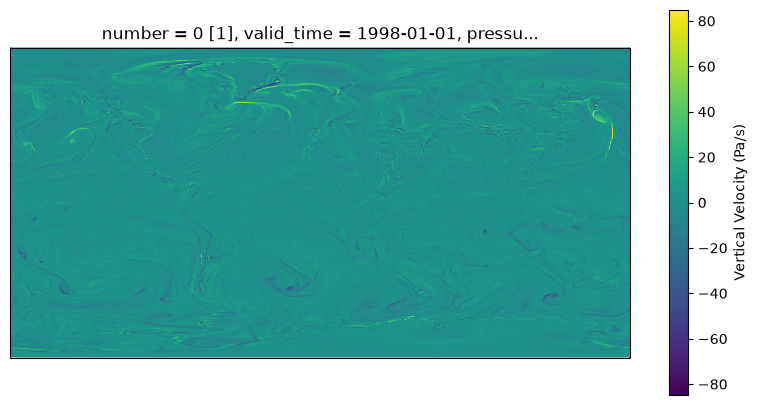

In [ ]:
proj = ccrs.PlateCarree()
#pc = ccrs.LambertConformal(central_longitude=0, central_latitude=45, standard_parallels=(30, 60))
fig, ax = plt.subplots(figsize=(10, 5), subplot_kw={'projection': proj})
vo.plot(ax=ax, transform=proj, cmap='viridis', cbar_kwargs={'label': 'Vertical Velocity (Pa/s)'})



In [31]:
lmin = 5
lmax = 42

vo_filtered_5 = SHTFilter(lmin=lmin, lmax=lmax, taper_val=0.1).filter(vo)

In [32]:
lmin=6
lmax=42
vo_filtered_6 = SHTFilter(lmin=lmin, lmax=lmax, taper_val=0.1).filter(vo)

In [33]:
diff_5 = vo - vo_filtered_5
diff_6 = vo - vo_filtered_6
diff_5_6 = vo_filtered_5 - vo_filtered_6

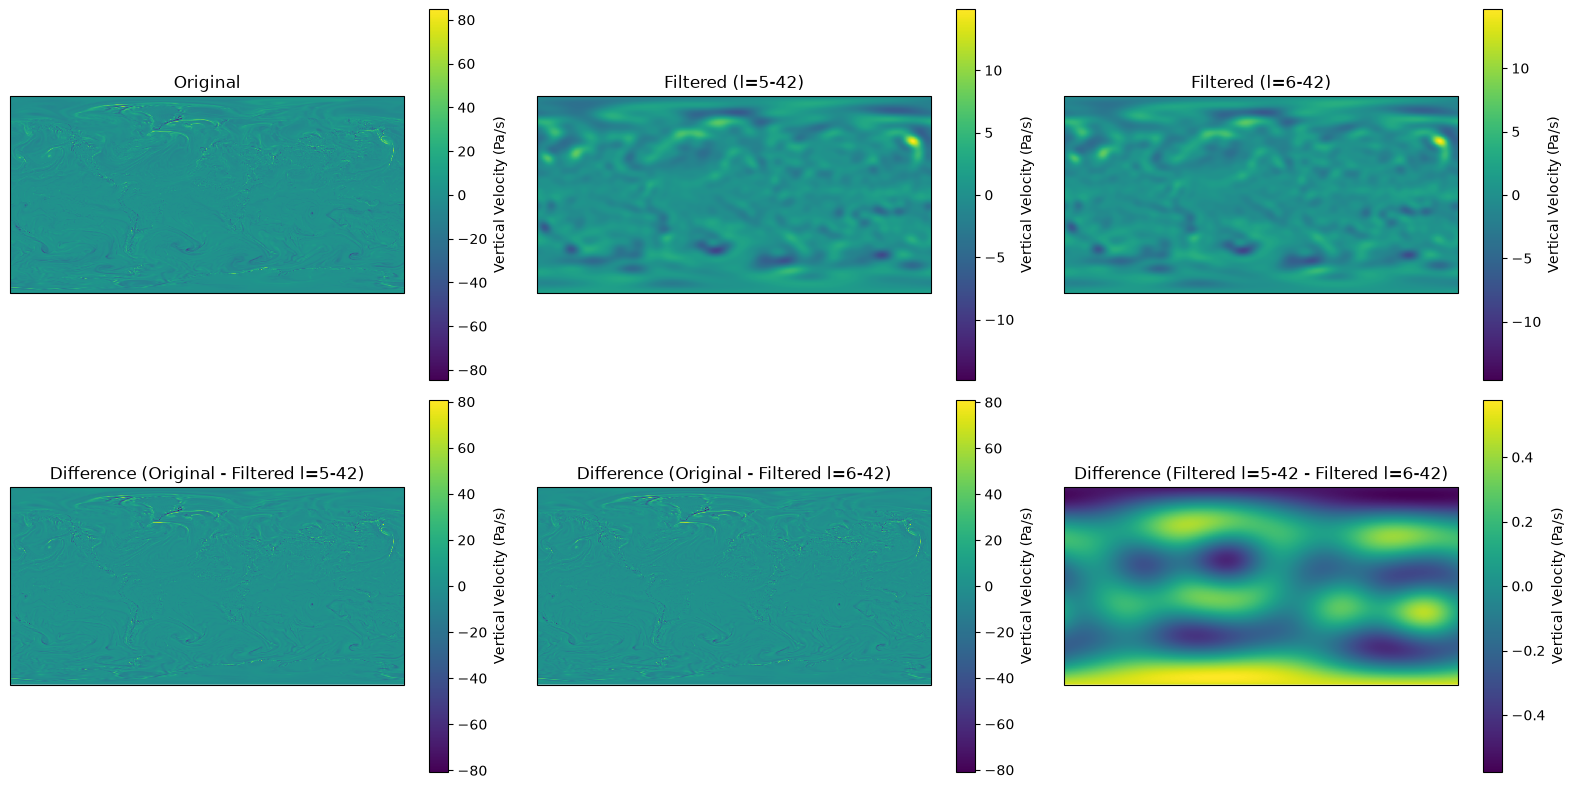

In [41]:
proj = ccrs.PlateCarree()
#pc = ccrs.LambertConformal(central_longitude=0, central_latitude=45, standard_parallels=(30, 60))
fig, ax = plt.subplots(2,3,figsize=(16, 8), subplot_kw={'projection': proj})
vo.plot(ax=ax[0,0], transform=proj, cmap='viridis', cbar_kwargs={'label': 'Vertical Velocity (Pa/s)'})
vo_filtered_5.plot(ax=ax[0,1], transform=proj, cmap='viridis', cbar_kwargs={'label': 'Vertical Velocity (Pa/s)'})
vo_filtered_6.plot(ax=ax[0,2], transform=proj, cmap='viridis', cbar_kwargs={'label': 'Vertical Velocity (Pa/s)'})

ax[0,0].set_title('Original')
ax[0,1].set_title('Filtered (l=5-42)')
ax[0,2].set_title('Filtered (l=6-42)')


diff_5.plot(ax=ax[1,0], transform=proj, cmap='viridis', cbar_kwargs={'label': 'Vertical Velocity (Pa/s)'})
diff_6.plot(ax=ax[1,1], transform=proj, cmap='viridis', cbar_kwargs={'label': 'Vertical Velocity (Pa/s)'})
diff_5_6.plot(ax=ax[1,2], transform=proj, cmap='viridis', cbar_kwargs={'label': 'Vertical Velocity (Pa/s)'})

ax[1,0].set_title('Difference (Original - Filtered l=5-42)')
ax[1,1].set_title('Difference (Original - Filtered l=6-42)')
ax[1,2].set_title('Difference (Filtered l=5-42 - Filtered l=6-42)')

plt.tight_layout()




/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.1

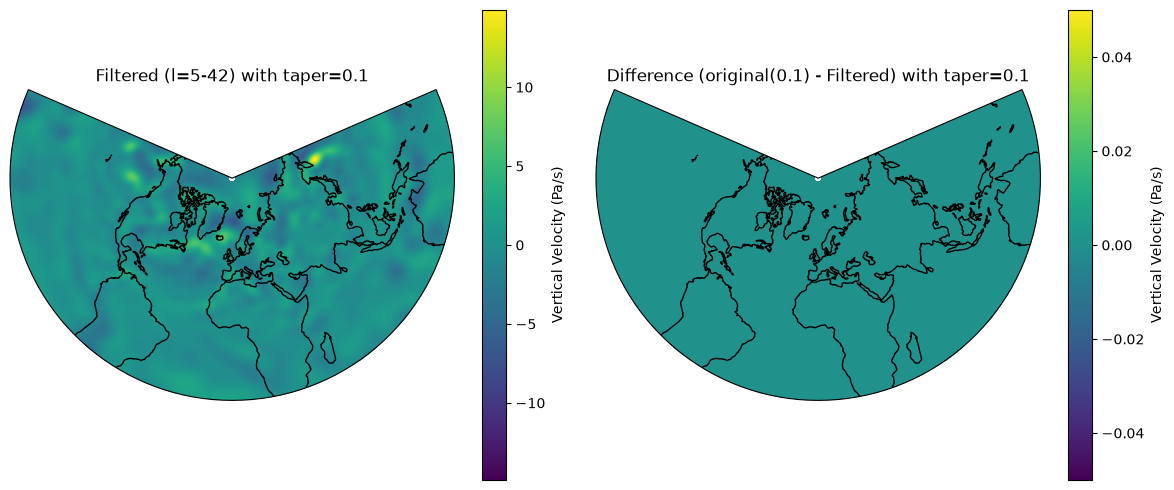

/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


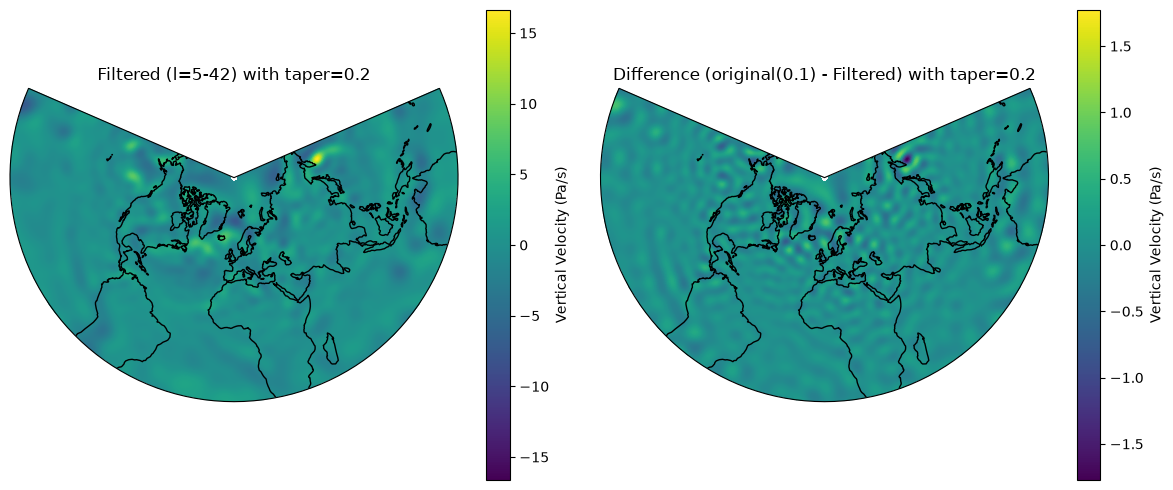

/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


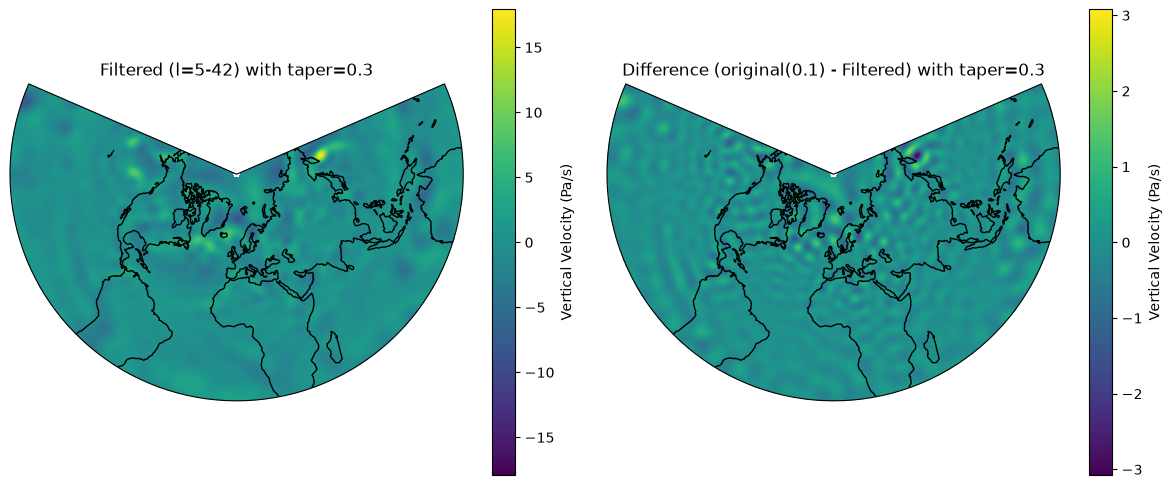

/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


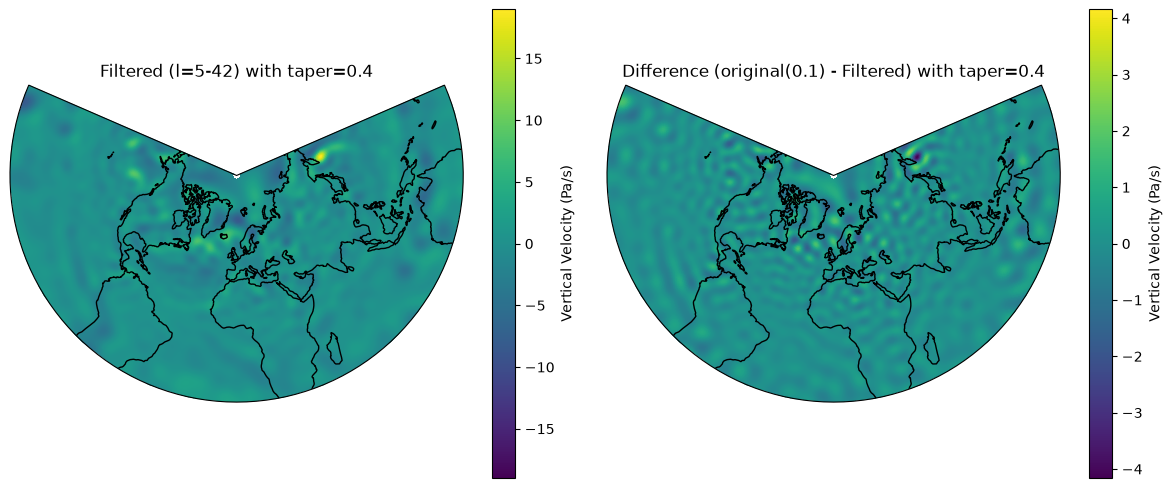

/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


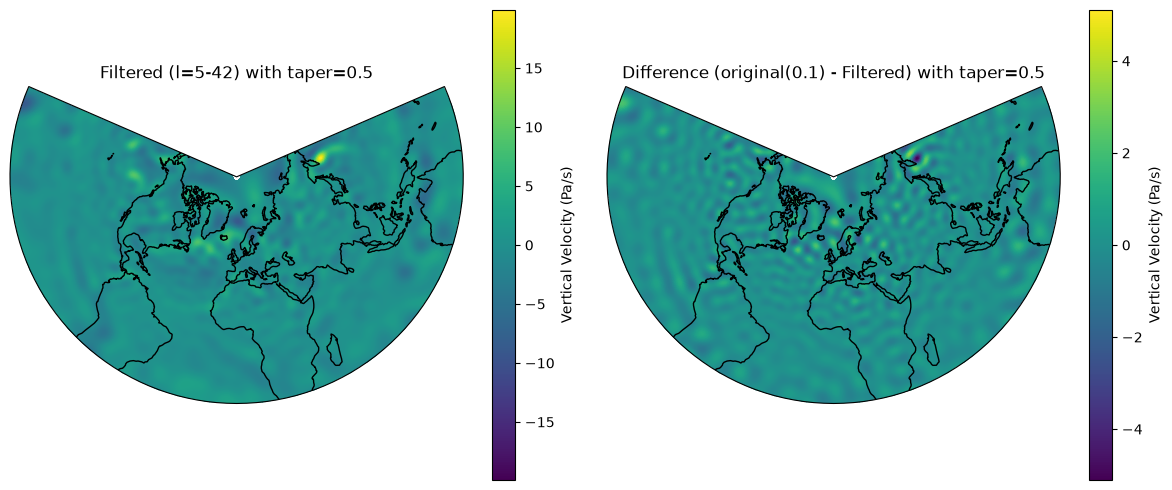

/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


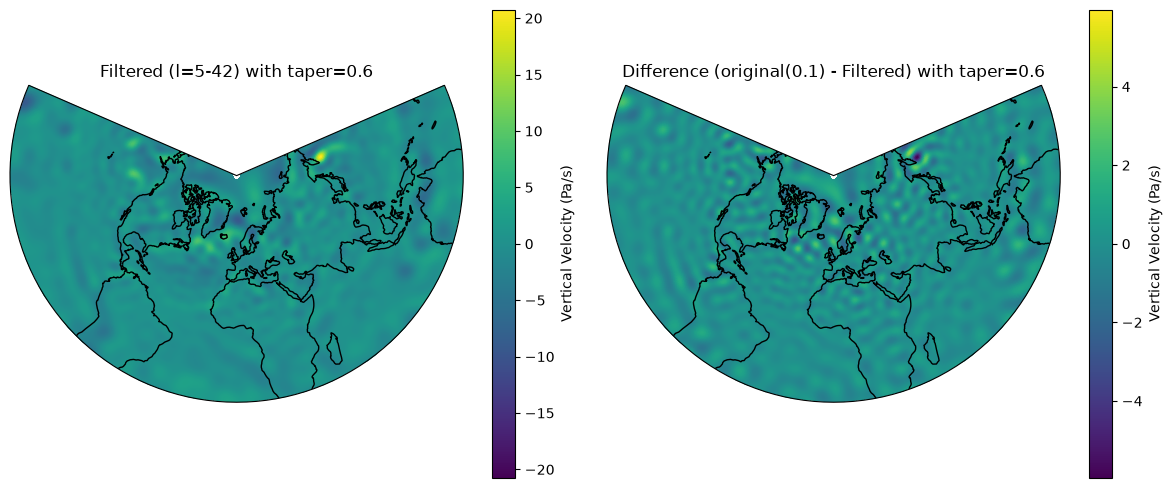

/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


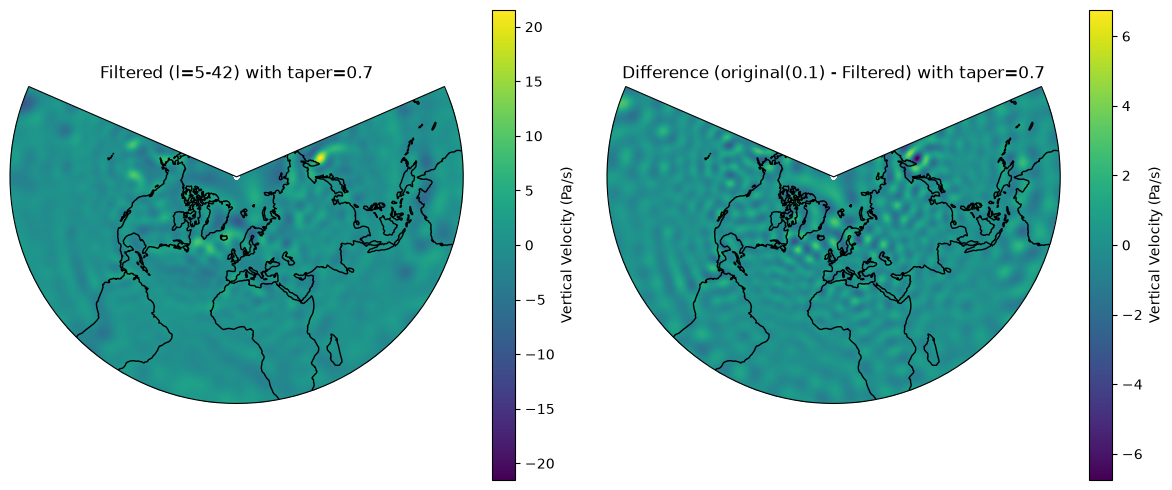

/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


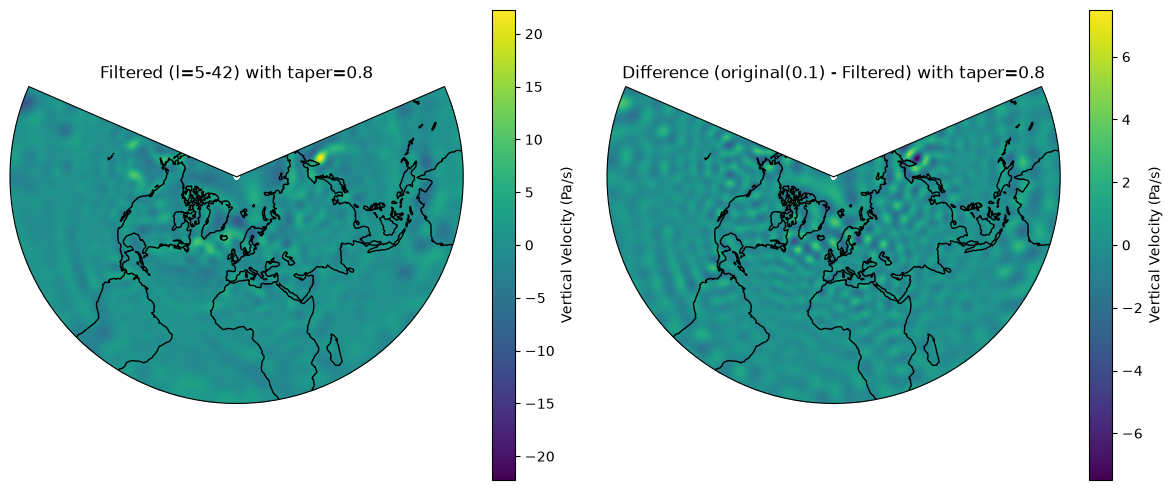

/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


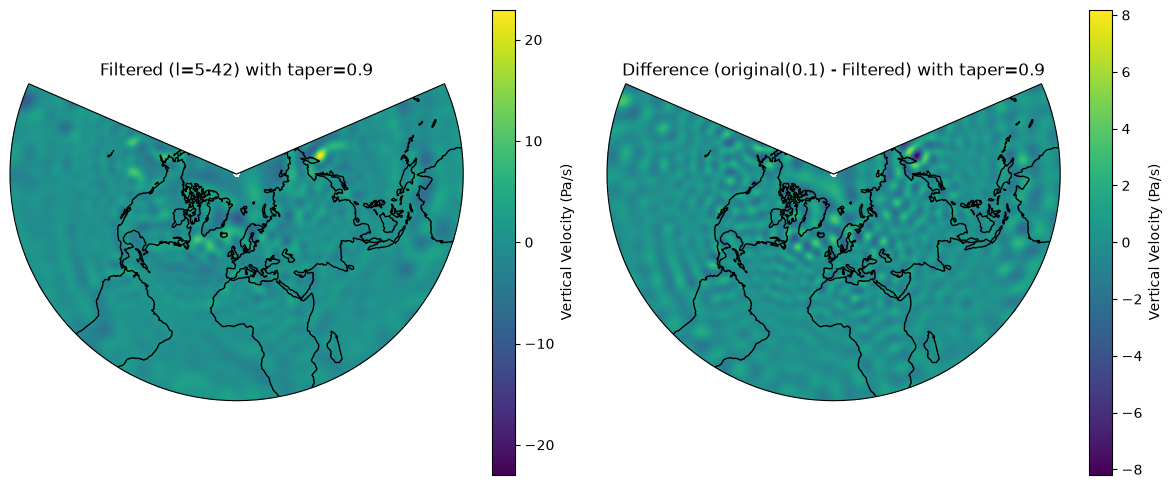

/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


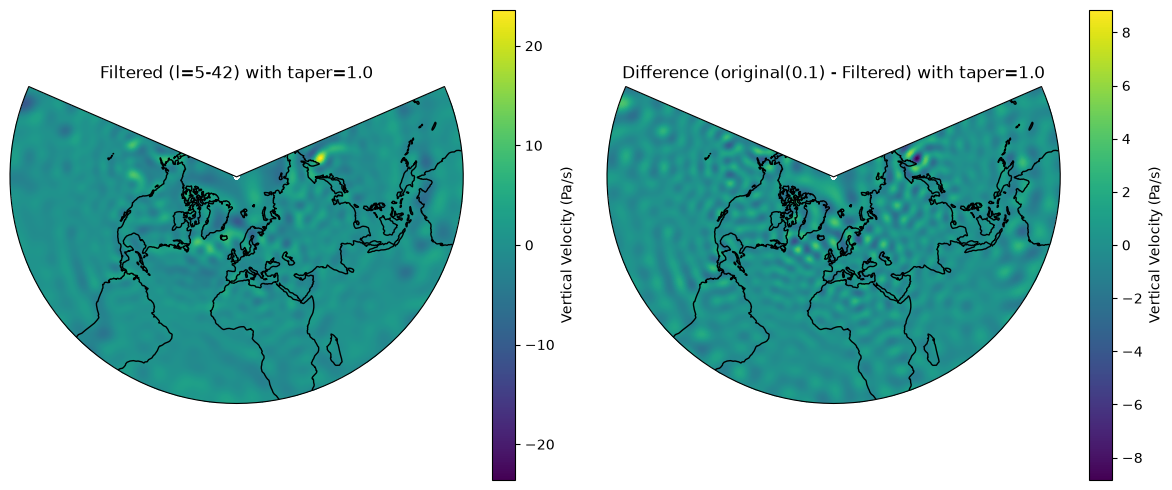

In [46]:
taper_vals = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

for taper_val in taper_vals:

    vo_filtered = SHTFilter(lmin=5, lmax=42, taper_val=taper_val).filter(vo)
    if taper_val == 0.1:
        orig = vo_filtered
    diff = orig - vo_filtered

    pc = ccrs.PlateCarree()
    proj = ccrs.LambertConformal(central_longitude=0, central_latitude=45)
    fig, ax = plt.subplots(1,2,figsize=(12, 5), subplot_kw={'projection': proj})
    ax[0].coastlines()
    ax[1].coastlines()
    vo_filtered.plot(ax=ax[0], transform=pc, cmap='viridis', cbar_kwargs={'label': 'Vertical Velocity (Pa/s)'})
    diff.plot(ax=ax[1], transform=pc, cmap='viridis', cbar_kwargs={'label': 'Vertical Velocity (Pa/s)'})

    ax[0].set_title(f'Filtered (l=5-42) with taper={taper_val}')
    ax[1].set_title(f'Difference (original(0.1) - Filtered) with taper={taper_val}')
    
    plt.tight_layout()